# CITS4012 Assignment 2 — Goal-Aware Contrastive Attention for PIQA

**Group: `GROUP_ID` (replace before submission)**

This notebook is the complete, from-scratch implementation accompanying the ACL report. It contains setup and data instructions, preprocessing, all model/baseline definitions, the fixed experiment matrix, saved training/evaluation evidence, attention visualisations, and reproducibility checks. No external training data or pretrained representation is used by the main model.

> The assignment refers to a provided code template, but no template file was present with the supplied brief and four dataset archives. The notebook therefore follows a conventional, fully executable Colab structure.


## Reproduction protocol

1. Open this notebook in Google Colab and select **Runtime → Run all**.
2. Upload the supplied `PIQA-...zip` to the Colab Files pane before the setup cell (or set `PROJECT_ROOT` to its Drive directory).
3. The fixed seed-2026 stratified validation split is created only from the supplied training file. Vocabulary fitting also uses training text only.
4. Validation accuracy selects checkpoints; held-out test labels are used only for the pre-specified final comparisons.
5. The full matrix trains three main seeds and one matched seed for each controlled ablation. Outputs are written to `results/`.

Python 3.10+, PyTorch 2.3+, pandas 2+, scikit-learn 1.3+, SciPy 1.10+, and Matplotlib 3.7+ are supported.


## 1. Environment and supplied data

In [ ]:
# Colab/runtime setup
# PyTorch is preinstalled on standard Colab runtimes. The remaining packages are lightweight.
%pip -q install "pandas>=2.0" "scikit-learn>=1.3" "scipy>=1.10" "matplotlib>=3.7"

from pathlib import Path
import zipfile

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "results"
OUTPUT_DIR.mkdir(exist_ok=True)

# Put the supplied PIQA zip in the Colab Files pane (or set PROJECT_ROOT to a Drive folder).
# This extracts only when train.jsonl is not already present.
if not list(PROJECT_ROOT.rglob("train-labels.lst")):
    archives = list(PROJECT_ROOT.glob("*PIQA*.zip"))
    if archives:
        with zipfile.ZipFile(archives[0]) as archive:
            archive.extractall(PROJECT_ROOT / "piqa_data")
    else:
        raise FileNotFoundError(
            "Upload the supplied PIQA-...zip to the Colab Files pane, then rerun this cell."
        )
print("Project root:", PROJECT_ROOT)


## 2. Complete implementation

In [ ]:
"""Reproducible PIQA experiments for CITS4012 Assignment 2.

The main model (GACA-BiGRU) is trained from scratch and uses goal-conditioned
additive attention plus a swap-equivariant contrastive candidate scorer.
"""

from __future__ import annotations

import argparse
import copy
import json
import math
import os
import random
import re
import sys
import time
from collections import Counter
from pathlib import Path

# Pip's Windows MKL wheels place runtime DLLs outside the normal DLL search path.
if sys.platform == "win32" and hasattr(os, "add_dll_directory"):
    _mkl = Path.home() / "AppData/Roaming/Python/Library/bin"
    if _mkl.exists():
        os.add_dll_directory(str(_mkl))

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from scipy import sparse
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, Dataset


PROJECT_SEED = 2026
TOKEN_RE = re.compile(r"[A-Za-z]+(?:'[A-Za-z]+)?|\d+(?:\.\d+)?|[^\w\s]", re.UNICODE)


def set_seed(seed: int) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(str(text).lower())


def find_data_dir(root: Path) -> Path:
    candidates = [
        root / "PIQA",
        root / "PIQA-20260927T040220Z-1-001" / "PIQA",
        root,
    ]
    for candidate in candidates:
        if (candidate / "train.jsonl").exists() and (candidate / "train-labels.lst").exists():
            return candidate
    matches = list(root.rglob("train-labels.lst"))
    if matches:
        return matches[0].parent
    raise FileNotFoundError("Could not find PIQA train.jsonl and train-labels.lst beneath " + str(root))


def load_split(data_dir: Path, split: str) -> pd.DataFrame:
    records = [json.loads(line) for line in (data_dir / f"{split}.jsonl").read_text(encoding="utf-8").splitlines()]
    labels = [int(x) for x in (data_dir / f"{split}-labels.lst").read_text(encoding="utf-8").splitlines()]
    if len(records) != len(labels):
        raise ValueError(f"{split}: {len(records)} records but {len(labels)} labels")
    frame = pd.DataFrame(records)
    frame["label"] = labels
    frame["row_id"] = np.arange(len(frame))
    return frame[["row_id", "goal", "sol1", "sol2", "label"]]


def split_data(train_all: pd.DataFrame):
    train_idx, val_idx = train_test_split(
        np.arange(len(train_all)),
        test_size=0.15,
        random_state=PROJECT_SEED,
        stratify=train_all["label"],
    )
    return train_all.iloc[train_idx].reset_index(drop=True), train_all.iloc[val_idx].reset_index(drop=True)


class Vocabulary:
    def __init__(self, texts, max_size=20000, min_freq=2):
        counts = Counter(token for text in texts for token in tokenize(text))
        ordered = sorted(counts.items(), key=lambda kv: (-kv[1], kv[0]))
        words = [word for word, freq in ordered if freq >= min_freq][: max_size - 2]
        self.itos = ["<pad>", "<unk>"] + words
        self.stoi = {word: idx for idx, word in enumerate(self.itos)}

    def encode(self, text, max_len):
        ids = [self.stoi.get(token, 1) for token in tokenize(text)][:max_len]
        return ids or [1]

    def __len__(self):
        return len(self.itos)


class PIQADataset(Dataset):
    def __init__(self, frame, vocab, max_goal=48, max_solution=64):
        self.frame = frame.reset_index(drop=True)
        self.items = []
        for row in self.frame.itertuples(index=False):
            self.items.append(
                (
                    vocab.encode(row.goal, max_goal),
                    vocab.encode(row.sol1, max_solution),
                    vocab.encode(row.sol2, max_solution),
                    int(row.label),
                    int(row.row_id),
                )
            )

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]


def collate(batch):
    goals, sol1s, sol2s, labels, row_ids = zip(*batch)

    def pad(sequences):
        lengths = torch.tensor([len(x) for x in sequences], dtype=torch.long)
        tensor = torch.zeros(len(sequences), int(lengths.max()), dtype=torch.long)
        for i, seq in enumerate(sequences):
            tensor[i, : len(seq)] = torch.tensor(seq, dtype=torch.long)
        return tensor, lengths

    goal, goal_len = pad(goals)
    sol1, sol1_len = pad(sol1s)
    sol2, sol2_len = pad(sol2s)
    return {
        "goal": goal,
        "goal_len": goal_len,
        "sol1": sol1,
        "sol1_len": sol1_len,
        "sol2": sol2,
        "sol2_len": sol2_len,
        "label": torch.tensor(labels, dtype=torch.long),
        "row_id": torch.tensor(row_ids, dtype=torch.long),
    }


def masked_mean(x, lengths):
    mask = torch.arange(x.size(1), device=x.device)[None, :] < lengths[:, None]
    return (x * mask.unsqueeze(-1)).sum(1) / lengths.clamp_min(1).unsqueeze(-1)


class GACABiGRU(nn.Module):
    """Goal-Aware Contrastive Attention BiGRU.

    mode controls controlled ablations:
      main: full model
      no_attention: mean pool solution states
      no_contrast: score each candidate without rival features
      simple_features: attention retained but only [goal; candidate] features
      mean_bigru: standard shared BiGRU mean-pooling neural baseline
    """

    def __init__(self, vocab_size, emb_dim=96, hidden=64, dropout=0.25, mode="main"):
        super().__init__()
        self.mode = mode
        dim = hidden * 2
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.encoder = nn.GRU(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)
        self.att_s = nn.Linear(dim, dim, bias=False)
        self.att_g = nn.Linear(dim, dim, bias=True)
        self.att_v = nn.Linear(dim, 1, bias=False)

        if mode == "mean_bigru":
            rep_dim = dim * 4
            scorer_in = rep_dim
        elif mode == "simple_features":
            rep_dim = dim * 2
            scorer_in = rep_dim * 3
        else:
            rep_dim = dim * 4
            scorer_in = rep_dim if mode == "no_contrast" else rep_dim * 3
        self.scorer = nn.Sequential(
            nn.Linear(scorer_in, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1),
        )

        nn.init.uniform_(self.embedding.weight, -0.08, 0.08)
        with torch.no_grad():
            self.embedding.weight[0].zero_()

    def encode(self, ids, lengths):
        embedded = self.dropout(self.embedding(ids))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, _ = self.encoder(packed)
        output, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=ids.size(1))
        return output

    def attend(self, solution_states, solution_lengths, goal_vector):
        energy = self.att_v(torch.tanh(self.att_s(solution_states) + self.att_g(goal_vector).unsqueeze(1))).squeeze(-1)
        mask = torch.arange(solution_states.size(1), device=solution_states.device)[None, :] < solution_lengths[:, None]
        energy = energy.masked_fill(~mask, -1e9)
        alpha = torch.softmax(energy, dim=1)
        attended = torch.bmm(alpha.unsqueeze(1), solution_states).squeeze(1)
        return attended, alpha

    def candidate_rep(self, goal_vector, solution_states, solution_lengths):
        if self.mode in {"no_attention", "mean_bigru"}:
            solution_vector = masked_mean(solution_states, solution_lengths)
            alpha = None
        else:
            solution_vector, alpha = self.attend(solution_states, solution_lengths, goal_vector)
        if self.mode == "simple_features":
            rep = torch.cat([goal_vector, solution_vector], dim=-1)
        else:
            rep = torch.cat(
                [goal_vector, solution_vector, goal_vector * solution_vector, (goal_vector - solution_vector).abs()], dim=-1
            )
        return rep, alpha

    def forward(self, goal, goal_len, sol1, sol1_len, sol2, sol2_len):
        goal_states = self.encode(goal, goal_len)
        sol1_states = self.encode(sol1, sol1_len)
        sol2_states = self.encode(sol2, sol2_len)
        goal_vector = masked_mean(goal_states, goal_len)
        rep1, alpha1 = self.candidate_rep(goal_vector, sol1_states, sol1_len)
        rep2, alpha2 = self.candidate_rep(goal_vector, sol2_states, sol2_len)

        if self.mode in {"no_contrast", "mean_bigru"}:
            z1, z2 = rep1, rep2
        else:
            product = rep1 * rep2
            z1 = torch.cat([rep1, rep1 - rep2, product], dim=-1)
            z2 = torch.cat([rep2, rep2 - rep1, product], dim=-1)
        logits = torch.cat([self.scorer(self.dropout(z1)), self.scorer(self.dropout(z2))], dim=1)
        return logits, alpha1, alpha2


def loaders(train, val, test, vocab, batch_size=128):
    datasets = [PIQADataset(x, vocab) for x in (train, val, test)]
    return (
        DataLoader(datasets[0], batch_size=batch_size, shuffle=True, collate_fn=collate, num_workers=0),
        DataLoader(datasets[1], batch_size=batch_size * 2, shuffle=False, collate_fn=collate, num_workers=0),
        DataLoader(datasets[2], batch_size=batch_size * 2, shuffle=False, collate_fn=collate, num_workers=0),
    )


@torch.no_grad()
def predict(model, loader, device="cpu"):
    model.eval()
    labels, predictions, probabilities, row_ids = [], [], [], []
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss(reduction="sum")
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        logits, _, _ = model(batch["goal"], batch["goal_len"], batch["sol1"], batch["sol1_len"], batch["sol2"], batch["sol2_len"])
        probs = torch.softmax(logits, dim=1)
        total_loss += criterion(logits, batch["label"]).item()
        labels.extend(batch["label"].cpu().tolist())
        predictions.extend(logits.argmax(1).cpu().tolist())
        probabilities.extend(probs[:, 1].cpu().tolist())
        row_ids.extend(batch["row_id"].cpu().tolist())
    return {
        "loss": total_loss / len(labels),
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "labels": labels,
        "predictions": predictions,
        "probability_label1": probabilities,
        "row_ids": row_ids,
    }


def train_neural(train, val, test, vocab, mode, seed, args, output_dir):
    set_seed(seed)
    train_loader, val_loader, test_loader = loaders(train, val, test, vocab, args.batch_size)
    model = GACABiGRU(len(vocab), args.embedding_dim, args.hidden_dim, args.dropout, mode=mode).to(args.device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=args.learning_rate, weight_decay=args.weight_decay)
    criterion = nn.CrossEntropyLoss()
    best_state, best_val, stale = None, -1.0, 0
    history = []
    start = time.time()

    for epoch in range(1, args.epochs + 1):
        model.train()
        total_loss, total_items = 0.0, 0
        for batch in train_loader:
            batch = {k: v.to(args.device) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            logits, _, _ = model(batch["goal"], batch["goal_len"], batch["sol1"], batch["sol1_len"], batch["sol2"], batch["sol2_len"])
            loss = criterion(logits, batch["label"])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
            optimizer.step()
            total_loss += loss.item() * len(batch["label"])
            total_items += len(batch["label"])
        val_metrics = predict(model, val_loader, args.device)
        row = {
            "epoch": epoch,
            "train_loss": total_loss / total_items,
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
        }
        history.append(row)
        print(f"{mode:15s} seed={seed:2d} epoch={epoch:02d} train_loss={row['train_loss']:.4f} val_acc={row['val_accuracy']:.4f} val_f1={row['val_macro_f1']:.4f}", flush=True)
        if val_metrics["accuracy"] > best_val + 1e-6:
            best_val = val_metrics["accuracy"]
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= args.patience:
                break

    model.load_state_dict(best_state)
    val_metrics = predict(model, val_loader, args.device)
    test_metrics = predict(model, test_loader, args.device)
    elapsed = time.time() - start
    stem = f"{mode}_seed{seed}"
    pd.DataFrame(history).to_csv(output_dir / f"{stem}_history.csv", index=False)
    prediction_frame = pd.DataFrame(
        {
            "row_id": test_metrics["row_ids"],
            "gold": test_metrics["labels"],
            "prediction": test_metrics["predictions"],
            "probability_label1": test_metrics["probability_label1"],
        }
    ).sort_values("row_id")
    prediction_frame.to_csv(output_dir / f"{stem}_test_predictions.csv", index=False)
    if mode == "main" and seed == args.seeds[0]:
        torch.save({"model_state": model.state_dict(), "vocab": vocab.itos, "config": vars(args)}, output_dir / "gaca_bigru_best.pt")
    summary = {
        "model": mode,
        "seed": seed,
        "parameters": sum(p.numel() for p in model.parameters()),
        "best_epoch": int(pd.DataFrame(history)["val_accuracy"].idxmax() + 1),
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "test_accuracy": test_metrics["accuracy"],
        "test_macro_f1": test_metrics["macro_f1"],
        "seconds": elapsed,
    }
    print("FINAL", json.dumps(summary), flush=True)
    return model, summary


def majority_baseline(train, val, test):
    majority = int(train["label"].mode().iloc[0])
    result = {"model": "majority", "seed": PROJECT_SEED, "parameters": 0, "best_epoch": 0}
    for name, frame in [("val", val), ("test", test)]:
        pred = np.full(len(frame), majority)
        result[f"{name}_accuracy"] = accuracy_score(frame["label"], pred)
        result[f"{name}_macro_f1"] = f1_score(frame["label"], pred, average="macro")
    result["seconds"] = 0.0
    return result


def tfidf_baseline(train, val, test, output_dir):
    start = time.time()
    corpus = pd.concat([train["goal"], train["sol1"], train["sol2"]], ignore_index=True)
    vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), max_features=30000, min_df=2, sublinear_tf=True)
    vectorizer.fit(corpus)

    def features(frame):
        g = vectorizer.transform(frame["goal"])
        s1 = vectorizer.transform(frame["sol1"])
        s2 = vectorizer.transform(frame["sol2"])
        # Pairwise difference plus difference in lexical goal overlap.
        return sparse.hstack([s1 - s2, g.multiply(s1) - g.multiply(s2)], format="csr")

    x_train, x_val, x_test = features(train), features(val), features(test)
    classifier = LogisticRegression(C=1.0, max_iter=1000, random_state=PROJECT_SEED, solver="liblinear")
    classifier.fit(x_train, train["label"])
    result = {"model": "tfidf_logreg", "seed": PROJECT_SEED, "parameters": int(x_train.shape[1]), "best_epoch": 0}
    for name, frame, x in [("val", val, x_val), ("test", test, x_test)]:
        pred = classifier.predict(x)
        result[f"{name}_accuracy"] = accuracy_score(frame["label"], pred)
        result[f"{name}_macro_f1"] = f1_score(frame["label"], pred, average="macro")
        if name == "test":
            pd.DataFrame({"row_id": frame["row_id"], "gold": frame["label"], "prediction": pred}).to_csv(
                output_dir / "tfidf_test_predictions.csv", index=False
            )
    result["seconds"] = time.time() - start
    return result


def bootstrap_accuracy_interval(labels, predictions, seed=PROJECT_SEED, n_boot=5000):
    labels, predictions = np.asarray(labels), np.asarray(predictions)
    rng = np.random.default_rng(seed)
    samples = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(labels), len(labels))
        samples[i] = np.mean(labels[idx] == predictions[idx])
    return np.quantile(samples, [0.025, 0.975]).tolist()


@torch.no_grad()
def save_attention_examples(model, frame, vocab, output_dir, device="cpu"):
    loader = DataLoader(PIQADataset(frame, vocab), batch_size=256, shuffle=False, collate_fn=collate)
    metrics = predict(model, loader, device)
    pred_by_id = {rid: pred for rid, pred in zip(metrics["row_ids"], metrics["predictions"])}
    confidence_by_id = {
        rid: (p if pred == 1 else 1 - p)
        for rid, pred, p in zip(metrics["row_ids"], metrics["predictions"], metrics["probability_label1"])
    }
    correct = [int(rid) for rid, gold in zip(frame["row_id"], frame["label"]) if pred_by_id[int(rid)] == int(gold)]
    wrong = [int(rid) for rid, gold in zip(frame["row_id"], frame["label"]) if pred_by_id[int(rid)] != int(gold)]
    chosen = [max(correct, key=confidence_by_id.get), max(wrong, key=confidence_by_id.get)]
    examples = []
    model.eval()
    for kind, rid in zip(["correct", "error"], chosen):
        row = frame.loc[frame["row_id"] == rid].iloc[0]
        one = collate([PIQADataset(pd.DataFrame([row]), vocab)[0]])
        one = {k: v.to(device) for k, v in one.items()}
        logits, a1, a2 = model(one["goal"], one["goal_len"], one["sol1"], one["sol1_len"], one["sol2"], one["sol2_len"])
        pred = int(logits.argmax(1).item())
        probs = torch.softmax(logits, 1).cpu().numpy()[0].tolist()
        tokens1, tokens2 = tokenize(row["sol1"])[:64], tokenize(row["sol2"])[:64]
        weights1 = a1[0, : len(tokens1)].cpu().numpy()
        weights2 = a2[0, : len(tokens2)].cpu().numpy()
        example = {
            "kind": kind,
            "row_id": rid,
            "goal": row["goal"],
            "sol1": row["sol1"],
            "sol2": row["sol2"],
            "gold": int(row["label"]),
            "prediction": pred,
            "probabilities": probs,
            "tokens1": tokens1,
            "attention1": weights1.tolist(),
            "tokens2": tokens2,
            "attention2": weights2.tolist(),
        }
        examples.append(example)

        fig, axes = plt.subplots(2, 1, figsize=(10, 3.5), constrained_layout=True)
        for ax, tokens, weights, title in [
            (axes[0], tokens1, weights1, "Solution 1"),
            (axes[1], tokens2, weights2, "Solution 2"),
        ]:
            shown = min(len(tokens), 28)
            ax.imshow(weights[:shown][None, :], aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(weights.max(), 0.15))
            ax.set_xticks(np.arange(shown), tokens[:shown], rotation=45, ha="right", fontsize=8)
            ax.set_yticks([])
            ax.set_ylabel(title, rotation=0, labelpad=40, va="center")
        fig.suptitle(f"{kind.title()} example: gold={int(row['label'])}, prediction={pred}")
        fig.savefig(output_dir / f"attention_{kind}.png", dpi=200, bbox_inches="tight")
        plt.close(fig)
    (output_dir / "attention_examples.json").write_text(json.dumps(examples, indent=2), encoding="utf-8")


def dataset_statistics(train_all, train, val, test, vocab):
    def lens(series):
        values = series.map(lambda x: len(tokenize(x)))
        return {"mean": float(values.mean()), "median": float(values.median()), "p95": float(values.quantile(0.95)), "max": int(values.max())}
    return {
        "sizes": {"provided_train": len(train_all), "train": len(train), "validation": len(val), "test": len(test)},
        "label1_fraction": {"train": float(train["label"].mean()), "validation": float(val["label"].mean()), "test": float(test["label"].mean())},
        "token_lengths": {"goal": lens(train_all["goal"]), "solution1": lens(train_all["sol1"]), "solution2": lens(train_all["sol2"])},
        "vocabulary_size": len(vocab),
    }


## 3. Dataset audit and leakage-safe split

In [1]:
# Load the official splits and create the fixed training-only validation split.
data_dir = find_data_dir(PROJECT_ROOT)
train_all = load_split(data_dir, "train")
test = load_split(data_dir, "test")
train, val = split_data(train_all)
vocab = Vocabulary(pd.concat([train["goal"], train["sol1"], train["sol2"]], ignore_index=True))
stats = dataset_statistics(train_all, train, val, test, vocab)
print(json.dumps(stats, indent=2))


{
  "sizes": {
    "provided_train": 16113,
    "train": 13696,
    "validation": 2417,
    "test": 1838
  },
  "label1_fraction": {
    "train": 0.5002190420560748,
    "validation": 0.5002068680182044,
    "test": 0.5048966267682263
  },
  "token_lengths": {
    "goal": {
      "mean": 7.806864022838702,
      "median": 8.0,
      "p95": 14.0,
      "max": 35
    },
    "solution1": {
      "mean": 21.22944206541302,
      "median": 14.0,
      "p95": 61.0,
      "max": 472
    },
    "solution2": {
      "mean": 21.235027617451745,
      "median": 14.0,
      "p95": 61.0,
      "max": 472
    }
  },
  "vocabulary_size": 10812
}


## 4. Architectural invariant

In [2]:
# Architecture invariant: swapping the alternatives must swap the two logits.
set_seed(13)
probe = GACABiGRU(len(vocab), emb_dim=96, hidden=64, dropout=0.25, mode="main")
probe.eval()
batch = next(iter(DataLoader(PIQADataset(train.iloc[:8], vocab), batch_size=8, collate_fn=collate)))
with torch.no_grad():
    original, _, _ = probe(batch["goal"], batch["goal_len"], batch["sol1"], batch["sol1_len"], batch["sol2"], batch["sol2_len"])
    swapped, _, _ = probe(batch["goal"], batch["goal_len"], batch["sol2"], batch["sol2_len"], batch["sol1"], batch["sol1_len"])
assert torch.allclose(original, swapped.flip(1), atol=1e-6)
print("Swap-equivariance check: PASS")
print(f"Main-model trainable parameters: {sum(p.numel() for p in probe.parameters()):,}")


Swap-equivariance check: PASS
Main-model trainable parameters: 1,330,049


## 5. Baselines, main runs, and controlled ablations

The matrix is fixed before final evaluation:

- majority and pairwise TF–IDF logistic-regression baselines;
- a standard shared mean-pooled BiGRU neural baseline;
- full GACA-BiGRU at seeds 13, 37, and 73;
- matched seed-13 ablations: no attention, no pair contrast, and simple concatenation features.


In [ ]:
# Full pre-specified experiment matrix. This cell is intentionally executable end-to-end.
# Expected time depends on runtime; a GPU is selected automatically when available.
from types import SimpleNamespace

args = SimpleNamespace(
    root=PROJECT_ROOT,
    output_dir=OUTPUT_DIR,
    epochs=6,
    patience=2,
    batch_size=256,
    embedding_dim=96,
    hidden_dim=64,
    dropout=0.25,
    learning_rate=2e-3,
    weight_decay=1e-4,
    grad_clip=5.0,
    device="cuda" if torch.cuda.is_available() else "cpu",
    seeds=[13, 37, 73],
)
torch.set_num_threads(min(8, os.cpu_count() or 1))
print("Device:", args.device)

summaries = [majority_baseline(train, val, test), tfidf_baseline(train, val, test, OUTPUT_DIR)]
main_model = None
for seed in args.seeds:
    model, summary = train_neural(train, val, test, vocab, "main", seed, args, OUTPUT_DIR)
    summaries.append(summary)
    if seed == args.seeds[0]:
        main_model = model

for mode in ["mean_bigru", "no_attention", "no_contrast", "simple_features"]:
    _, summary = train_neural(train, val, test, vocab, mode, args.seeds[0], args, OUTPUT_DIR)
    summaries.append(summary)

results = pd.DataFrame(summaries)
results.to_csv(OUTPUT_DIR / "all_results.csv", index=False)
main_rows = results[results["model"] == "main"]
aggregate = {
    "main_test_accuracy_mean": float(main_rows["test_accuracy"].mean()),
    "main_test_accuracy_std": float(main_rows["test_accuracy"].std(ddof=1)),
    "main_test_macro_f1_mean": float(main_rows["test_macro_f1"].mean()),
    "main_test_macro_f1_std": float(main_rows["test_macro_f1"].std(ddof=1)),
}
seed13 = pd.read_csv(OUTPUT_DIR / "main_seed13_test_predictions.csv")
aggregate["main_seed13_accuracy_95ci"] = bootstrap_accuracy_interval(seed13["gold"], seed13["prediction"])
(OUTPUT_DIR / "aggregate_results.json").write_text(json.dumps(aggregate, indent=2))
save_attention_examples(main_model, test, vocab, OUTPUT_DIR, args.device)
display(results)
print(json.dumps(aggregate, indent=2))


## 6. Saved training and evaluation evidence

In [3]:
SAVED_TRAINING_LOGS = '[main_seed13_history]\nepoch=01 train_loss=0.6905 val_loss=0.6722 val_acc=0.5863 val_f1=0.5862\nepoch=02 train_loss=0.6335 val_loss=0.6682 val_acc=0.6024 val_f1=0.6024\nepoch=03 train_loss=0.5564 val_loss=0.7030 val_acc=0.6024 val_f1=0.6024\nepoch=04 train_loss=0.4932 val_loss=0.7494 val_acc=0.5983 val_f1=0.5983\n[main_seed37_history]\nepoch=01 train_loss=0.6911 val_loss=0.6766 val_acc=0.5921 val_f1=0.5921\nepoch=02 train_loss=0.6330 val_loss=0.6722 val_acc=0.5896 val_f1=0.5896\nepoch=03 train_loss=0.5549 val_loss=0.6880 val_acc=0.6003 val_f1=0.6003\nepoch=04 train_loss=0.4943 val_loss=0.7583 val_acc=0.5892 val_f1=0.5892\nepoch=05 train_loss=0.4311 val_loss=0.8243 val_acc=0.5991 val_f1=0.5991\n[main_seed73_history]\nepoch=01 train_loss=0.6914 val_loss=0.6776 val_acc=0.5867 val_f1=0.5867\nepoch=02 train_loss=0.6373 val_loss=0.6818 val_acc=0.5912 val_f1=0.5912\nepoch=03 train_loss=0.5621 val_loss=0.7015 val_acc=0.5904 val_f1=0.5904\nepoch=04 train_loss=0.5013 val_loss=0.7320 val_acc=0.5838 val_f1=0.5838\n[mean_bigru_seed13_history]\nepoch=01 train_loss=0.6935 val_loss=0.6926 val_acc=0.5619 val_f1=0.5619\nepoch=02 train_loss=0.6773 val_loss=0.6715 val_acc=0.5879 val_f1=0.5879\nepoch=03 train_loss=0.6056 val_loss=0.6871 val_acc=0.5863 val_f1=0.5863\nepoch=04 train_loss=0.5482 val_loss=0.7092 val_acc=0.5875 val_f1=0.5875\n[no_attention_seed13_history]\nepoch=01 train_loss=0.6908 val_loss=0.6745 val_acc=0.5834 val_f1=0.5833\nepoch=02 train_loss=0.6325 val_loss=0.6650 val_acc=0.6003 val_f1=0.6003\nepoch=03 train_loss=0.5528 val_loss=0.6955 val_acc=0.5970 val_f1=0.5970\nepoch=04 train_loss=0.4890 val_loss=0.7376 val_acc=0.5966 val_f1=0.5966\n[no_contrast_seed13_history]\nepoch=01 train_loss=0.6934 val_loss=0.6926 val_acc=0.5606 val_f1=0.5606\nepoch=02 train_loss=0.6789 val_loss=0.6700 val_acc=0.5908 val_f1=0.5908\nepoch=03 train_loss=0.6117 val_loss=0.6798 val_acc=0.5788 val_f1=0.5788\nepoch=04 train_loss=0.5499 val_loss=0.7074 val_acc=0.5871 val_f1=0.5871\n[simple_features_seed13_history]\nepoch=01 train_loss=0.6903 val_loss=0.6722 val_acc=0.5966 val_f1=0.5966\nepoch=02 train_loss=0.6319 val_loss=0.6710 val_acc=0.5970 val_f1=0.5970\nepoch=03 train_loss=0.5584 val_loss=0.6882 val_acc=0.5900 val_f1=0.5900\nepoch=04 train_loss=0.5078 val_loss=0.7200 val_acc=0.5966 val_f1=0.5966\n'
SAVED_RESULTS = '          model  seed  parameters  best_epoch  val_accuracy  val_macro_f1  test_accuracy  test_macro_f1  seconds\n       majority  2026           0           0         50.02         33.34          50.49          33.55      0.0\n   tfidf_logreg  2026       60000           0         60.61         60.60          59.47          59.45      4.1\n           main    13     1330049           2         60.24         60.24          60.94          60.93    219.7\n           main    37     1330049           3         60.03         60.03          60.28          60.28    270.4\n           main    73     1330049           2         59.12         59.12          60.72          60.72    219.5\n     mean_bigru    13     1198977           2         58.79         58.79          59.03          59.03    212.2\n   no_attention    13     1330049           2         60.03         60.03          60.39          60.39    213.4\n    no_contrast    13     1198977           2         59.08         59.08          58.49          58.48    247.0\nsimple_features    13     1231745           2         59.70         59.70          59.14          59.14    219.7\n\nAggregate main-model results:\n{\n  "main_test_accuracy_mean": 0.6064562930721799,\n  "main_test_accuracy_std": 0.0033243204170880555,\n  "main_test_macro_f1_mean": 0.6064295482558054,\n  "main_test_macro_f1_std": 0.0033015625501055584,\n  "main_seed13_accuracy_95ci": [\n    0.586493471164309,\n    0.6311207834602829\n  ]\n}\n'
# Saved evidence from the completed run used in the report.
# Re-running the experiment cell above regenerates these CSV-backed logs and values.
print(SAVED_TRAINING_LOGS)
print(SAVED_RESULTS)


[main_seed13_history]
epoch=01 train_loss=0.6905 val_loss=0.6722 val_acc=0.5863 val_f1=0.5862
epoch=02 train_loss=0.6335 val_loss=0.6682 val_acc=0.6024 val_f1=0.6024
epoch=03 train_loss=0.5564 val_loss=0.7030 val_acc=0.6024 val_f1=0.6024
epoch=04 train_loss=0.4932 val_loss=0.7494 val_acc=0.5983 val_f1=0.5983
[main_seed37_history]
epoch=01 train_loss=0.6911 val_loss=0.6766 val_acc=0.5921 val_f1=0.5921
epoch=02 train_loss=0.6330 val_loss=0.6722 val_acc=0.5896 val_f1=0.5896
epoch=03 train_loss=0.5549 val_loss=0.6880 val_acc=0.6003 val_f1=0.6003
epoch=04 train_loss=0.4943 val_loss=0.7583 val_acc=0.5892 val_f1=0.5892
epoch=05 train_loss=0.4311 val_loss=0.8243 val_acc=0.5991 val_f1=0.5991
[main_seed73_history]
epoch=01 train_loss=0.6914 val_loss=0.6776 val_acc=0.5867 val_f1=0.5867
epoch=02 train_loss=0.6373 val_loss=0.6818 val_acc=0.5912 val_f1=0.5912
epoch=03 train_loss=0.5621 val_loss=0.7015 val_acc=0.5904 val_f1=0.5904
epoch=04 train_loss=0.5013 val_loss=0.7320 val_acc=0.5838 val_f1=0.583

## Qualitative attention analysis

The saved visualisations below use the seed-13 checkpoint selected only by validation accuracy.

- **Correct case (row 1766)** — Goal: “To protect your car from scratches in your garage,”  
  Gold/prediction: solution 1; confidence 97.2%. Attention on the correct solution peaks at *level* and *noodles*, while the rival highlights *pillows*.
- **Failure (row 1207)** — Goal: “to clean shoelaces”  
  Gold: solution 1; prediction: solution 2 with 92.9% confidence. The model attends strongly to *acetone* but lacks the material/chemical knowledge to treat it as unsafe.

Attention weights are diagnostic evidence, not causal explanations of the final MLP decision.


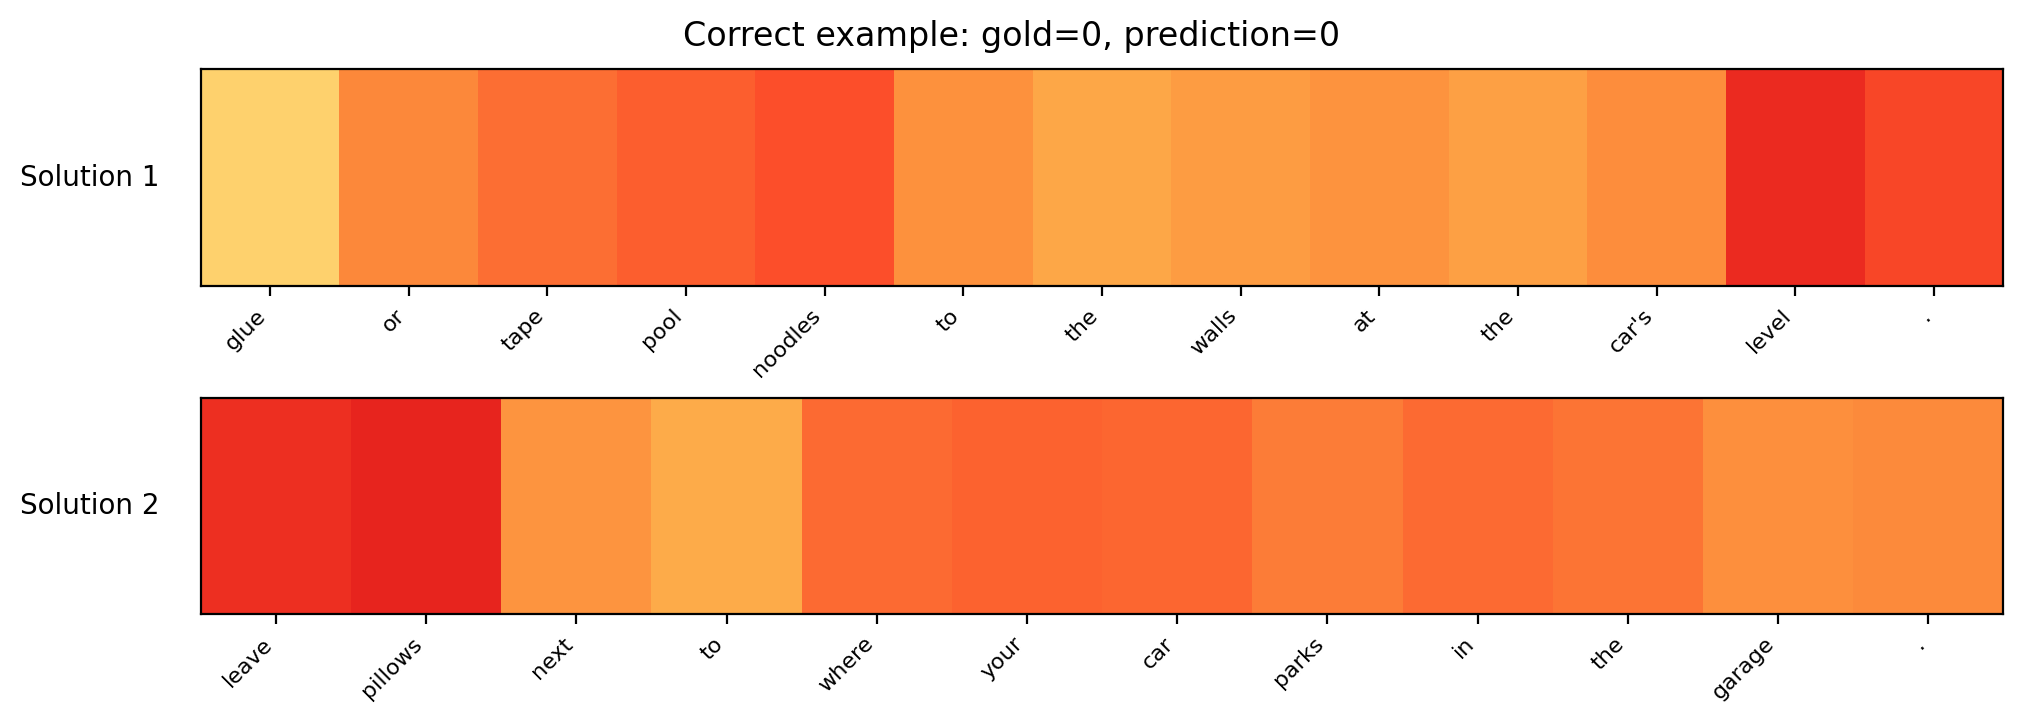

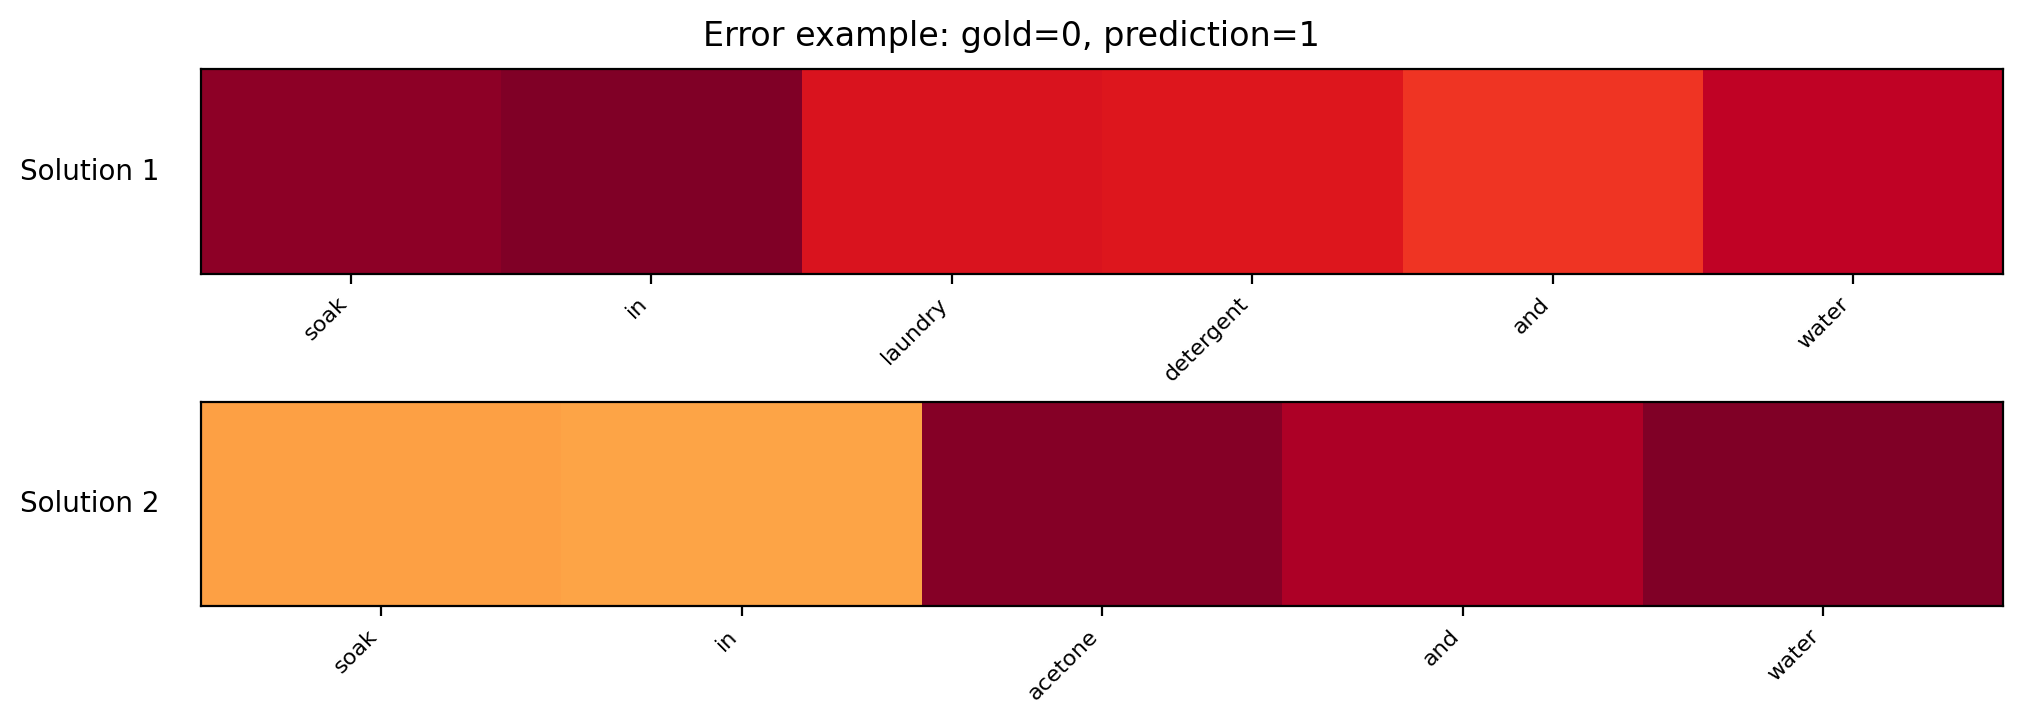

In [4]:
# Regenerated after the training cell; saved outputs from the report run are shown here.
from IPython.display import Image, display
display(Image(filename=str(OUTPUT_DIR / "attention_correct.png")))
display(Image(filename=str(OUTPUT_DIR / "attention_error.png")))


## 7. Submission consistency checklist

- Main model is trained from random initialisation and contains an explicit attention mechanism.
- Dataset sizes, split seed, vocabulary, truncation, hyperparameters, parameter count, epochs, metrics, and numerical results match the report.
- All baseline values come from this project’s own executions.
- The test split is not used for fitting or checkpoint selection.
- Histories, per-example test predictions, aggregate metrics, checkpoint, and attention JSON/PNGs are regenerated in `results/`.
- Before submission, replace `GROUP_ID` in the notebook filename/title and the report, and replace the report’s contribution placeholder.
